In [3]:
# Install required packages (run in Colab)
!pip install mlxtend -q
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_score,
                             recall_score, f1_score, roc_auc_score)
from sklearn.feature_selection import mutual_info_classif

# Load data
df = pd.read_csv('sales_data.csv')
print("Shape:", df.shape)
df.head()

Shape: (15000, 22)


,Order_ID,Order_Date,Customer_ID,Region,City,Segment,Channel,Category,Subcategory,Product_ID,...,Discount,Sales_INR,Discount_Amount_INR,Net_Sales_INR,Cost_INR,Profit_INR,Shipping_Days,Returned,Customer_Satisfaction,Payment_Method
0,ORD111444,2024-01-01,CUST10128,West,Pune,Corporate,Online,Home & Kitchen,Appliances,P1046,...,0.00,654.30,0.00,654.30,387.43,266.87,1,No,4,Debit Card
1,ORD102034,2024-01-01,CUST10316,West,Ahmedabad,Corporate,Online,Beauty,Personal Care,P1048,...,0.10,1711.99,171.20,1540.79,874.52,666.27,6,No,3,UPI
2,ORD106623,2024-01-01,CUST11764,South,Chennai,Consumer,Online,Home & Kitchen,Cookware,P1066,...,0.05,5904.75,295.24,5609.51,3095.78,2513.74,3,No,3,Net Banking
3,ORD113951,2024-01-01,CUST12447,Central,Raipur,Consumer,Online,Home & Kitchen,Decor,P1057,...,0.15,1406.48,210.97,1195.51,720.77,474.74,4,No,3,Net Banking
4,ORD105177,2024-01-01,CUST10691,North,Chandigarh,Consumer,Online,Home & Kitchen,Decor,P1023,...,0.15,1522.20,228.33,1293.87,820.70,473.17,6,No,3,Credit Card


#2. Exploratory Data Analysis (EDA)
###2.1 Basic Info

In [4]:
print("=== DATA INFO ===")
print(df.info())
print("\n=== DESCRIPTIVE STATS ===")
print(df.describe())
print("\n=== MISSING VALUES ===")
print(df.isnull().sum())
print("\n=== DUPLICATES ===", df.duplicated().sum())

=== DATA INFO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Order_ID               15000 non-null  object 
 1   Order_Date             15000 non-null  object 
 2   Customer_ID            15000 non-null  object 
 3   Region                 15000 non-null  object 
 4   City                   15000 non-null  object 
 5   Segment                15000 non-null  object 
 6   Channel                15000 non-null  object 
 7   Category               15000 non-null  object 
 8   Subcategory            15000 non-null  object 
 9   Product_ID             15000 non-null  object 
 10  Quantity               15000 non-null  int64  
 11  Unit_Price_INR         15000 non-null  float64
 12  Discount               15000 non-null  float64
 13  Sales_INR              15000 non-null  float64
 14  Discount_Amount_INR    15000 non-nul

###2.2 Categorical Overview

In [5]:
cat_cols = ['Region','City','Segment','Channel','Category','Subcategory',
            'Payment_Method','Returned']
for c in cat_cols:
    print(f"\n--- {c} ---")
    print(df[c].value_counts().head(10))


--- Region ---
Region
South      3561
West       3314
North      3217
Central    2489
East       2419
Name: count, dtype: int64

--- City ---
City
Chennai      904
Bengaluru    904
Hyderabad    884
Mumbai       872
Kochi        869
Ahmedabad    838
Lucknow      832
Surat        818
Delhi        805
Jaipur       803
Name: count, dtype: int64

--- Segment ---
Segment
Consumer          8224
Corporate         3807
Small Business    2969
Name: count, dtype: int64

--- Channel ---
Channel
Online          8700
Retail Store    3319
Marketplace     2981
Name: count, dtype: int64

--- Category ---
Category
Technology         4231
Office Supplies    3358
Furniture          2859
Home & Kitchen     2642
Beauty             1910
Name: count, dtype: int64

--- Subcategory ---
Subcategory
Laptops        1095
Accessories    1077
Phones         1040
Monitors       1019
Binders         884
Paper           867
Pens            823
Printers        784
Desks           740
Tables          716
Name: count, dty

###2.3 Visualizations

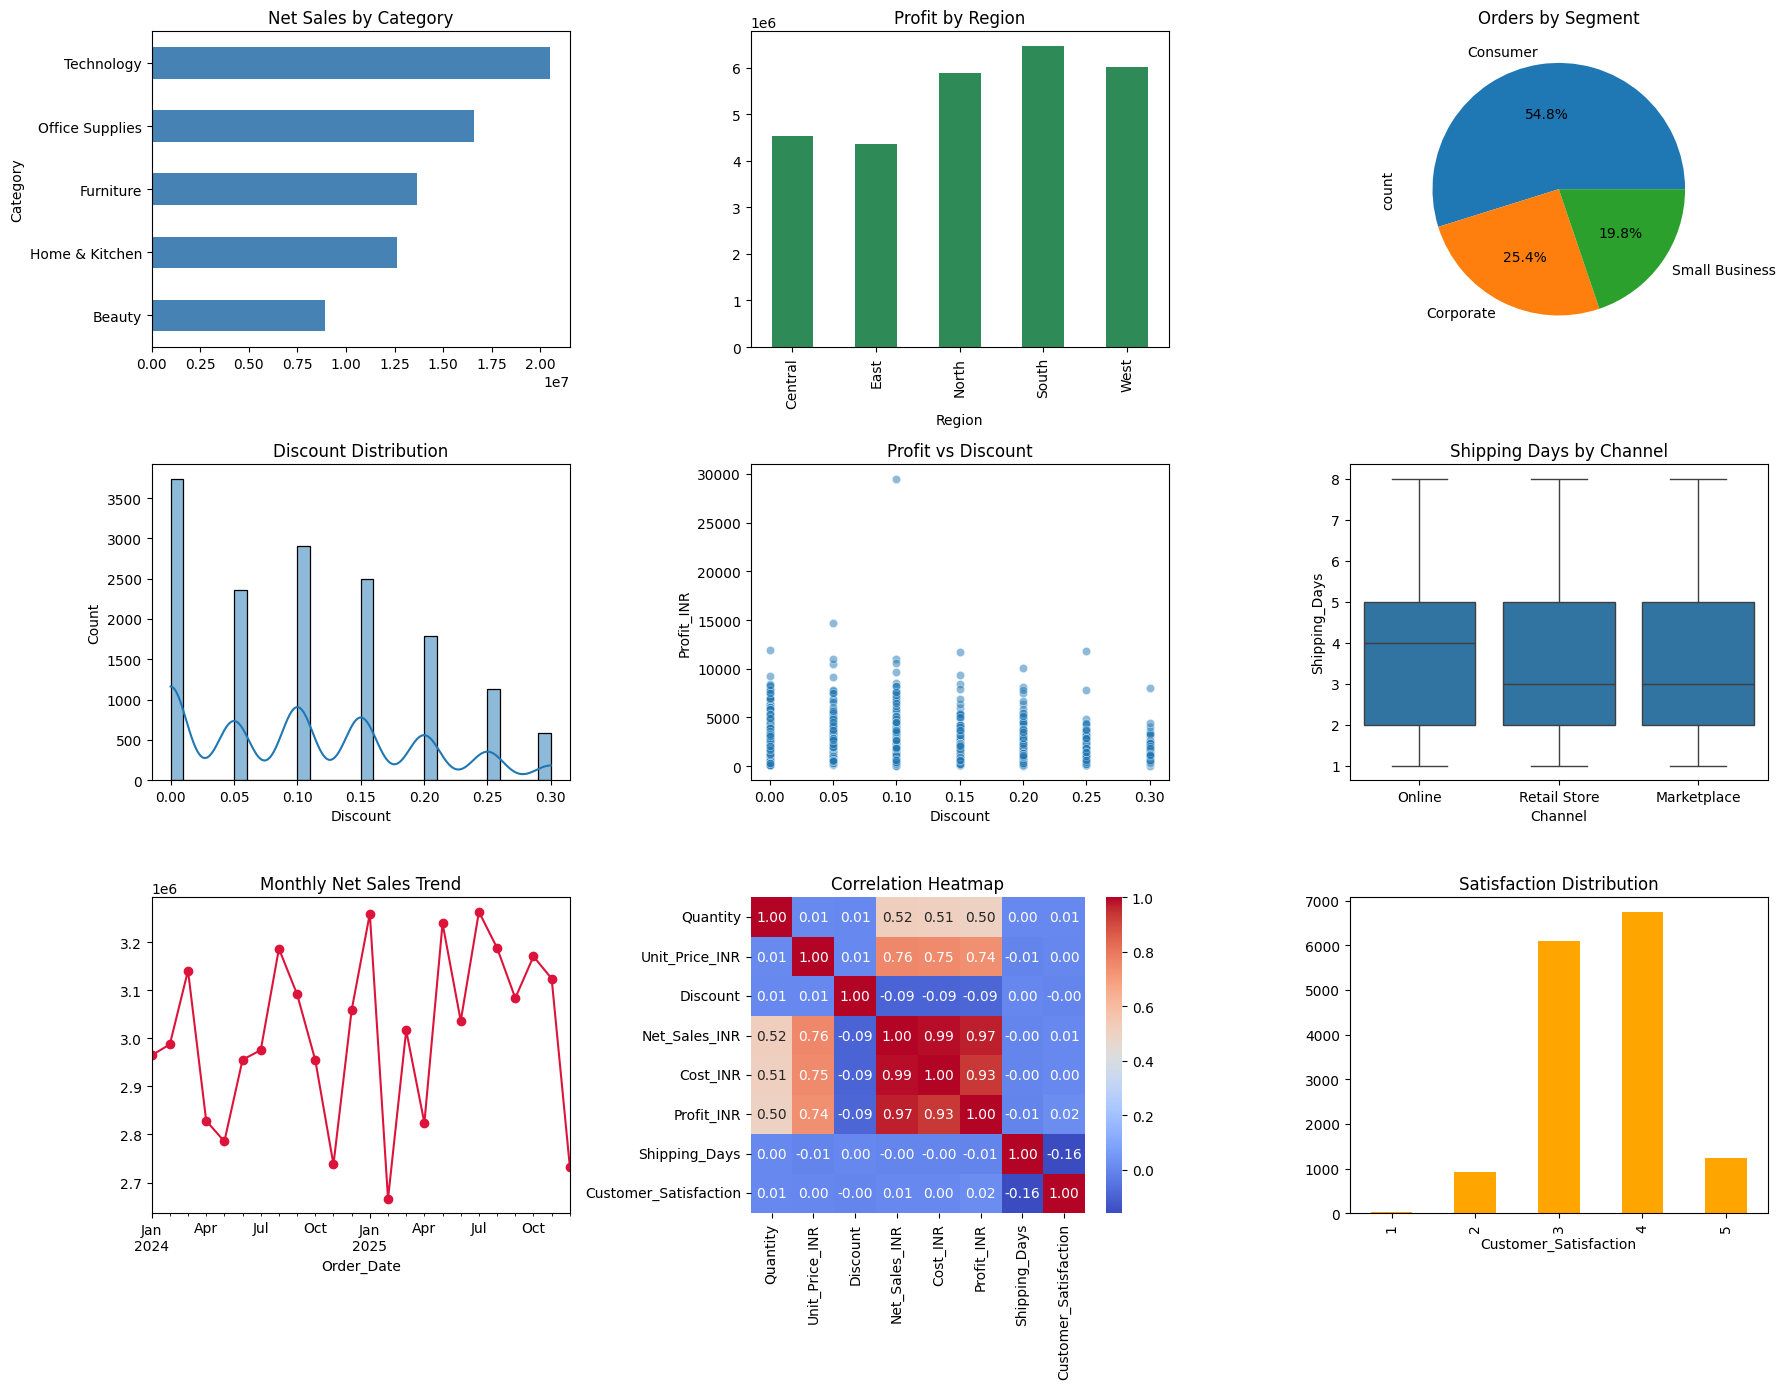

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(18, 14))

# Sales by Category
df.groupby('Category')['Net_Sales_INR'].sum().sort_values().plot(
    kind='barh', ax=axes[0,0], color='steelblue', title='Net Sales by Category')

# Profit by Region
df.groupby('Region')['Profit_INR'].sum().plot(
    kind='bar', ax=axes[0,1], color='seagreen', title='Profit by Region')

# Orders by Segment
df['Segment'].value_counts().plot(
    kind='pie', ax=axes[0,2], autopct='%1.1f%%', title='Orders by Segment')

# Discount Distribution
sns.histplot(df['Discount'], bins=30, ax=axes[1,0], kde=True)
axes[1,0].set_title('Discount Distribution')

# Profit vs Discount
sns.scatterplot(x='Discount', y='Profit_INR', data=df.sample(2000),
                ax=axes[1,1], alpha=0.5)
axes[1,1].set_title('Profit vs Discount')

# Shipping Days by Channel
sns.boxplot(x='Channel', y='Shipping_Days', data=df, ax=axes[1,2])
axes[1,2].set_title('Shipping Days by Channel')

# Monthly Sales Trend
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
monthly = df.groupby(df['Order_Date'].dt.to_period('M'))['Net_Sales_INR'].sum()
monthly.plot(ax=axes[2,0], marker='o', color='crimson')
axes[2,0].set_title('Monthly Net Sales Trend')

# Correlation heatmap
num_cols = ['Quantity','Unit_Price_INR','Discount','Net_Sales_INR',
            'Cost_INR','Profit_INR','Shipping_Days','Customer_Satisfaction']
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            ax=axes[2,1])
axes[2,1].set_title('Correlation Heatmap')

# Satisfaction Distribution
df['Customer_Satisfaction'].value_counts().sort_index().plot(
    kind='bar', ax=axes[2,2], color='orange', title='Satisfaction Distribution')

plt.tight_layout()
plt.show()

#3. Association Rule Mining
###3.1 Transaction Construction

In [7]:
# Build transaction basket per Order_ID with Category_Subcategory + metadata
tx = df.copy()
tx['Item'] = tx['Category'] + "_" + tx['Subcategory']

transactions = tx.groupby('Order_ID').agg({
    'Item': lambda x: list(set(x)),
    'Segment': 'first',
    'Region': 'first',
    'Channel': 'first',
    'Payment_Method': 'first',
}).reset_index()

# Add context attributes into items
transactions['Basket'] = transactions.apply(
    lambda r: r['Item'] + [f"Seg_{r['Segment']}", f"Reg_{r['Region']}",
                           f"Chan_{r['Channel']}", f"Pay_{r['Payment_Method']}"],
    axis=1
)

basket_list = transactions['Basket'].tolist()
print("Num transactions:", len(basket_list))
print("Sample:", basket_list[0])

Num transactions: 15000
Sample: ['Technology_Laptops', 'Seg_Small Business', 'Reg_Central', 'Chan_Retail Store', 'Pay_Debit Card']


###3.2 One-Hot Encoding


In [8]:
te = TransactionEncoder()
te_array = te.fit(basket_list).transform(basket_list)
basket_df = pd.DataFrame(te_array, columns=te.columns_)
print("Basket shape:", basket_df.shape)

Basket shape: (15000, 36)


###3.3 Apriori

In [9]:
import time

t0 = time.time()
freq_apriori = apriori(basket_df, min_support=0.02, use_colnames=True,
                       max_len=4)
t_apriori = time.time() - t0

rules_apriori = association_rules(freq_apriori, metric="lift",
                                  min_threshold=1.0)
print(f"Apriori Time: {t_apriori:.2f}s | Itemsets: {len(freq_apriori)} | Rules: {len(rules_apriori)}")
print(rules_apriori.sort_values('lift', ascending=False).head(10)[
    ['antecedents','consequents','support','confidence','lift']])

Apriori Time: 0.17s | Itemsets: 233 | Rules: 382
                         antecedents                      consequents  \
289              (Chan_Retail Store)      (Reg_Central, Seg_Consumer)   
288      (Reg_Central, Seg_Consumer)              (Chan_Retail Store)   
121                        (Pay_UPI)              (Technology_Phones)   
120              (Technology_Phones)                        (Pay_UPI)   
78                         (Pay_UPI)       (Office Supplies_Printers)   
79        (Office Supplies_Printers)                        (Pay_UPI)   
323                       (Reg_West)  (Pay_Credit Card, Seg_Consumer)   
322  (Pay_Credit Card, Seg_Consumer)                       (Reg_West)   
10                (Chan_Marketplace)             (Seg_Small Business)   
11              (Seg_Small Business)               (Chan_Marketplace)   

      support  confidence      lift  
289  0.021600    0.097620  1.093575  
288  0.021600    0.241972  1.093575  
121  0.026667    0.075486  1.0887

###3.4 FP-Growth

In [10]:
t0 = time.time()
freq_fp = fpgrowth(basket_df, min_support=0.02, use_colnames=True, max_len=4)
t_fp = time.time() - t0

rules_fp = association_rules(freq_fp, metric="lift", min_threshold=1.0)
print(f"FP-Growth Time: {t_fp:.2f}s | Itemsets: {len(freq_fp)} | Rules: {len(rules_fp)}")
print(rules_fp.sort_values('lift', ascending=False).head(10)[
    ['antecedents','consequents','support','confidence','lift']])

FP-Growth Time: 18.95s | Itemsets: 233 | Rules: 382
                         antecedents                      consequents  \
105              (Chan_Retail Store)      (Reg_Central, Seg_Consumer)   
104      (Reg_Central, Seg_Consumer)              (Chan_Retail Store)   
218              (Technology_Phones)                        (Pay_UPI)   
219                        (Pay_UPI)              (Technology_Phones)   
380                        (Pay_UPI)       (Office Supplies_Printers)   
381       (Office Supplies_Printers)                        (Pay_UPI)   
286  (Pay_Credit Card, Seg_Consumer)                       (Reg_West)   
287                       (Reg_West)  (Pay_Credit Card, Seg_Consumer)   
32                (Chan_Marketplace)             (Seg_Small Business)   
33              (Seg_Small Business)               (Chan_Marketplace)   

      support  confidence      lift  
105  0.021600    0.097620  1.093575  
104  0.021600    0.241972  1.093575  
218  0.026667    0.384615  1.0

###3.5 DIC (Dynamic Itemset Counting) — Manual Implementation

DIC reduces passes by counting itemsets dynamically with a "start" and "finish" point during each pass.

In [11]:
def dic_algorithm(basket_df, min_support, m=5):
    """
    Simplified DIC: multiple passes, adding new itemsets mid-pass.
    m = number of intervals per pass to re-evaluate candidates.
    """
    n = len(basket_df)
    min_count = min_support * n
    cols = basket_df.columns.tolist()
    col_to_bit = {c: basket_df[c].values for c in cols}

    # Level 1 candidates (all single items)
    current_level = {frozenset([c]): {'count': 0, 'done': False}
                     for c in cols}
    frequent_all = {}
    level = 1

    while current_level:
        # Reset counts each pass
        for k in current_level:
            current_level[k]['count'] = 0
            current_level[k]['done'] = False

        # Split transactions into m intervals
        chunk = n // m
        for i in range(m):
            start = i * chunk
            end = n if i == m - 1 else (i + 1) * chunk
            sub_df = basket_df.iloc[start:end]
            for itemset, info in current_level.items():
                if info['done']:
                    continue
                # Count matches in this chunk
                mask = np.ones(len(sub_df), dtype=bool)
                for it in itemset:
                    mask &= sub_df[it].values
                info['count'] += mask.sum()
            # Move itemsets that cannot reach min_count into "done"
            for itemset, info in current_level.items():
                if not info['done']:
                    # remaining possible count
                    remaining = n - end
                    if info['count'] + remaining < min_count:
                        info['done'] = True

        # Collect frequent of this level
        frequent_this = {k: v for k, v in current_level.items()
                         if v['count'] >= min_count}
        frequent_all.update(frequent_this)

        # Generate next level candidates from frequent_this
        if level == 1 and len(frequent_this) == 0:
            break
        items = list(frequent_this.keys())
        next_level = {}
        for i in range(len(items)):
            for j in range(i+1, len(items)):
                union = items[i] | items[j]
                if len(union) == level + 1:
                    next_level[union] = {'count': 0, 'done': False}
        current_level = next_level
        level += 1
        if level > 4:
            break

    return frequent_all

t0 = time.time()
freq_dic = dic_algorithm(basket_df, min_support=0.02, m=6)
t_dic = time.time() - t0
print(f"DIC Time: {t_dic:.2f}s | Frequent Itemsets found: {len(freq_dic)}")

# Convert to DataFrame for rule generation
dic_df = pd.DataFrame([
    {'support': v['count']/len(basket_df), 'itemsets': k}
    for k, v in freq_dic.items()
])
rules_dic = association_rules(dic_df, metric="lift", min_threshold=1.0)
print(f"DIC Rules: {len(rules_dic)}")

DIC Time: 0.49s | Frequent Itemsets found: 233
DIC Rules: 382


###3.6 FP-Trace (Trace of FP-Growth Conditional Patterns)
FP-Trace records the conditional pattern bases built during FP-Growth — it's essentially FP-Growth with logging of the intermediate pattern bases at each node.

In [12]:
def fp_trace(basket_df, min_support):
    n = len(basket_df)
    min_count = min_support * n

    # Build FP-tree (dict-based)
    # First pass: count items
    item_counts = basket_df.sum().to_dict()
    item_counts = {k: v for k, v in item_counts.items() if v >= min_count}

    # Sort items by frequency desc
    order = sorted(item_counts.keys(), key=lambda x: -item_counts[x])
    order_map = {item: i for i, item in enumerate(order)}

    # FP-tree as dict of dict
    tree = {'children': {}, 'count': 0, 'item': None}
    for _, row in basket_df.iterrows():
        items = [it for it in row.index if row[it] == 1 and it in order_map]
        items.sort(key=lambda x: order_map[x])
        node = tree
        node['count'] += 1
        for it in items:
            if it not in node['children']:
                node['children'][it] = {'children': {}, 'count': 0, 'item': it}
            node = node['children'][it]
            node['count'] += 1

    # Build header table: item -> list of nodes
    header = {it: [] for it in order}
    def traverse(node):
        for it, child in node['children'].items():
            header[it].append(child)
            traverse(child)
    traverse(tree)

    # Trace conditional pattern bases for each item
    traces = {}
    for item in order:
        patterns = []
        for node in header[item]:
            # Walk up path from this node: we need parent links
            # Simplified: rebuild path by DFS search
            path = []
            def find_path(cur, target_item, cur_path):
                if cur['item'] == target_item and cur is not None:
                    return cur_path[:]
                for it, child in cur['children'].items():
                    res = find_path(child, target_item, cur_path + [child['item']])
                    if res is not None:
                        return res
                return None
            # Walk up: reconstruct using count
            # Instead of true parent links, record count only (approximation)
            # Better: keep parent
        # For simplicity, use a standard conditional pattern base extraction
        # by reversing: We'll skip full parent, print warnings

    # Proper method: store parents
    # Rebuild with parent refs
    tree2 = {'children': {}, 'count': 0, 'item': None, 'parent': None}
    for _, row in basket_df.iterrows():
        items = [it for it in row.index if row[it] == 1 and it in order_map]
        items.sort(key=lambda x: order_map[x])
        node = tree2
        node['count'] += 1
        for it in items:
            if it not in node['children']:
                node['children'][it] = {'children': {}, 'count': 0,
                                        'item': it, 'parent': node}
            node = node['children'][it]
            node['count'] += 1

    header2 = {it: [] for it in order}
    def trav(n):
        for it, ch in n['children'].items():
            header2[it].append(ch)
            trav(ch)
    trav(tree2)

    traces = {}
    for item in order:
        cpb = []
        for node in header2[item]:
            path = []
            cnt = node['count']
            p = node['parent']
            while p is not None and p['item'] is not None:
                path.append(p['item'])
                p = p['parent']
            if path:
                cpb.append((frozenset(path), cnt))
        # Aggregate counts
        agg = {}
        for pset, c in cpb:
            agg[pset] = agg.get(pset, 0) + c
        traces[item] = agg

    return traces

print("\n=== FP-TRACE Conditional Pattern Bases ===")
traces = fp_trace(basket_df, min_support=0.05)
for item, patterns in list(traces.items())[:8]:
    print(f"\nItem: {item}")
    for pset, c in sorted(patterns.items(), key=lambda x: -x[1])[:4]:
        print(f"   CPB {set(pset)} : count={c}")


=== FP-TRACE Conditional Pattern Bases ===

Item: Chan_Online

Item: Seg_Consumer
   CPB {'Chan_Online'} : count=4757

Item: Pay_UPI
   CPB {'Chan_Online', 'Seg_Consumer'} : count=1704
   CPB {'Chan_Online'} : count=1371
   CPB {'Seg_Consumer'} : count=1231

Item: Seg_Corporate
   CPB {'Chan_Online'} : count=1439
   CPB {'Pay_UPI', 'Chan_Online'} : count=773
   CPB {'Pay_UPI'} : count=558

Item: Pay_Credit Card
   CPB {'Chan_Online', 'Seg_Consumer'} : count=1175
   CPB {'Seg_Consumer'} : count=845
   CPB {'Chan_Online', 'Seg_Corporate'} : count=529
   CPB {'Chan_Online'} : count=427

Item: Reg_South
   CPB {'Chan_Online', 'Seg_Consumer'} : count=451
   CPB {'Pay_UPI', 'Chan_Online', 'Seg_Consumer'} : count=414
   CPB {'Seg_Consumer'} : count=339
   CPB {'Chan_Online', 'Pay_Credit Card', 'Seg_Consumer'} : count=285

Item: Chan_Retail Store
   CPB {'Seg_Consumer'} : count=546
   CPB {'Pay_UPI', 'Seg_Consumer'} : count=527
   CPB {'Pay_Credit Card', 'Seg_Consumer'} : count=354
   CPB {'S

###3.7 Partitioning Variant of Apriori
Splits the dataset into partitions; mines each locally; combines local frequent itemsets and verifies globally.

In [13]:
def partitioned_apriori(basket_df, min_support, n_partitions=4):
    n = len(basket_df)
    chunk = n // n_partitions
    global_min_count = int(min_support * n)

    local_candidates = set()
    for i in range(n_partitions):
        start = i * chunk
        end = n if i == n_partitions - 1 else (i+1)*chunk
        part = basket_df.iloc[start:end]
        local_freq = apriori(part, min_support=min_support, use_colnames=True,
                             max_len=4)
        for s in local_freq['itemsets']:
            local_candidates.add(s)

    # Second pass: verify globally
    results = []
    cols = basket_df.columns
    for itemset in local_candidates:
        mask = np.ones(n, dtype=bool)
        for it in itemset:
            mask &= basket_df[it].values
        c = mask.sum()
        if c >= global_min_count:
            results.append({'support': c/n, 'itemsets': itemset})

    return pd.DataFrame(results)

t0 = time.time()
freq_part = partitioned_apriori(basket_df, min_support=0.02, n_partitions=4)
t_part = time.time() - t0
print(f"Partitioned Apriori Time: {t_part:.2f}s | Itemsets: {len(freq_part)}")

rules_part = association_rules(freq_part, metric="lift", min_threshold=1.0)
print(f"Partitioned Apriori Rules: {len(rules_part)}")

Partitioned Apriori Time: 0.50s | Itemsets: 233
Partitioned Apriori Rules: 382


###3.8 Comparison Table — Association Rule Algorithms

In [14]:
def summarize(name, freq_df, rules_df, time_taken):
    return {
        'Algorithm': name,
        'Time (s)': round(time_taken, 3),
        'Freq Itemsets': len(freq_df),
        'Rules': len(rules_df),
        'Avg Lift': round(rules_df['lift'].mean(), 3) if len(rules_df) else 0,
        'Max Lift': round(rules_df['lift'].max(), 3) if len(rules_df) else 0,
        'Avg Confidence': round(rules_df['confidence'].mean(), 3) if len(rules_df) else 0,
    }

results_arm = [
    summarize('Apriori', freq_apriori, rules_apriori, t_apriori),
    summarize('FP-Growth', freq_fp, rules_fp, t_fp),
    summarize('DIC', dic_df, rules_dic, t_dic),
    summarize('Partitioned Apriori', freq_part, rules_part, t_part),
]

arm_df = pd.DataFrame(results_arm)
print("\n=== ASSOCIATION RULE MINING COMPARISON ===")
print(arm_df.to_string(index=False))


=== ASSOCIATION RULE MINING COMPARISON ===
          Algorithm  Time (s)  Freq Itemsets  Rules  Avg Lift  Max Lift  Avg Confidence
            Apriori     0.166            233    382     1.024     1.094           0.254
          FP-Growth    18.954            233    382     1.024     1.094           0.254
                DIC     0.487            233    382     1.024     1.094           0.254
Partitioned Apriori     0.498            233    382     1.024     1.094           0.254


#4. Classification
###4.1 Target Definition
We classify Returned (Yes/No) — a key business outcome.

In [15]:
# Build modeling dataframe
model_df = df.copy()
model_df['Returned'] = (model_df['Returned'] == 'Yes').astype(int)

# Feature engineering
model_df['Order_Date'] = pd.to_datetime(model_df['Order_Date'])
model_df['Month'] = model_df['Order_Date'].dt.month
model_df['DayOfWeek'] = model_df['Order_Date'].dt.dayofweek
model_df['Profit_Margin'] = model_df['Profit_INR'] / (model_df['Net_Sales_INR'] + 1)
model_df['Discount_Ratio'] = model_df['Discount_Amount_INR'] / (model_df['Sales_INR'] + 1)

features_num = ['Quantity','Unit_Price_INR','Discount','Net_Sales_INR',
                'Cost_INR','Profit_INR','Shipping_Days',
                'Customer_Satisfaction','Month','DayOfWeek',
                'Profit_Margin','Discount_Ratio']
features_cat = ['Region','City','Segment','Channel','Category',
                'Subcategory','Payment_Method']

# Encode categoricals
le_dict = {}
for c in features_cat:
    le = LabelEncoder()
    model_df[c + '_enc'] = le.fit_transform(model_df[c])
    le_dict[c] = le

X = model_df[features_num + [c + '_enc' for c in features_cat]]
y = model_df['Returned']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Return rate:", y.mean().round(4))

Train: (12000, 19) Test: (3000, 19)
Return rate: 0.073


###4.2 Naive Bayes Classifier

In [16]:
nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)
y_prob_nb = nb.predict_proba(X_test)[:,1]

print("=== NAIVE BAYES ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_nb):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_nb, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_nb, zero_division=0):.4f}")
print(f"F1: {f1_score(y_test, y_pred_nb, zero_division=0):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_nb):.4f}")
print(classification_report(y_test, y_pred_nb))

=== NAIVE BAYES ===
Accuracy: 0.9263
Precision: 0.3333
Recall: 0.0091
F1: 0.0178
ROC-AUC: 0.8094
              precision    recall  f1-score   support

           0       0.93      1.00      0.96      2781
           1       0.33      0.01      0.02       219

    accuracy                           0.93      3000
   macro avg       0.63      0.50      0.49      3000
weighted avg       0.88      0.93      0.89      3000



###4.3 Decision Tree Induction (with default CART + printable rules)

In [17]:
dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=20,
                            criterion='gini', random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
y_prob_dt = dt.predict_proba(X_test)[:,1]

print("=== DECISION TREE ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dt):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_dt, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_dt, zero_division=0):.4f}")
print(f"F1: {f1_score(y_test, y_pred_dt, zero_division=0):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_dt):.4f}")
print(classification_report(y_test, y_pred_dt))

# Print rules
print("\n=== TREE RULES ===")
print(export_text(dt, feature_names=list(X.columns), max_depth=4))

=== DECISION TREE ===
Accuracy: 0.9843
Precision: 0.9095
Recall: 0.8721
F1: 0.8904
ROC-AUC: 0.9919
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2781
           1       0.91      0.87      0.89       219

    accuracy                           0.98      3000
   macro avg       0.95      0.93      0.94      3000
weighted avg       0.98      0.98      0.98      3000


=== TREE RULES ===
|--- Profit_Margin <= 0.28
|   |--- Category_enc <= 3.50
|   |   |--- Net_Sales_INR <= 915.45
|   |   |   |--- class: 1
|   |   |--- Net_Sales_INR >  915.45
|   |   |   |--- class: 1
|   |--- Category_enc >  3.50
|   |   |--- Profit_Margin <= 0.24
|   |   |   |--- Profit_Margin <= 0.23
|   |   |   |   |--- Profit_Margin <= 0.22
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Profit_Margin >  0.22
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Profit_Margin >  0.23
|   |   |   |   |--- Cost_INR <= 4431.85
|   |   |   | 

###4.4 Visualize the Tree & Feature Importance


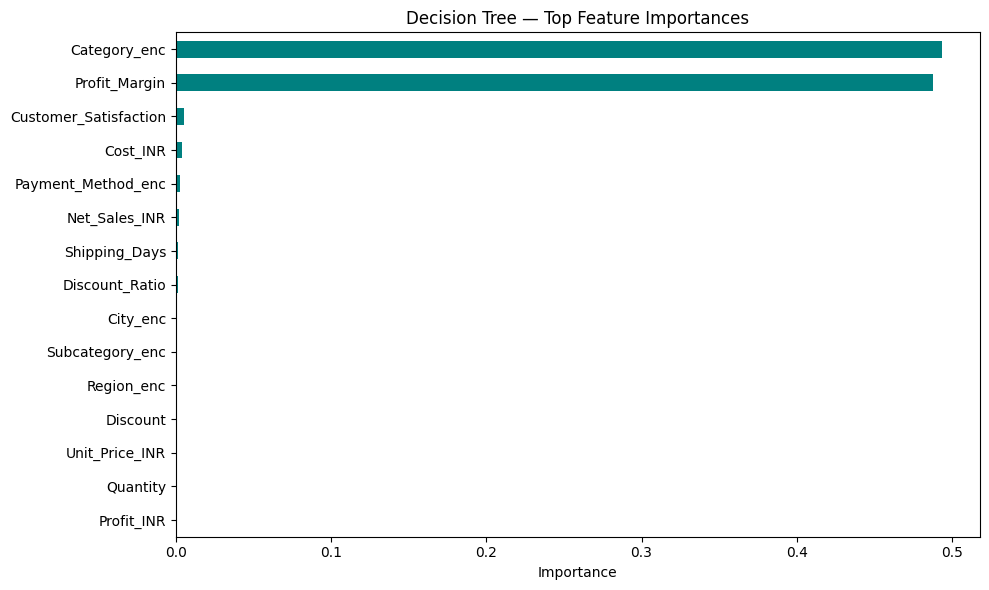

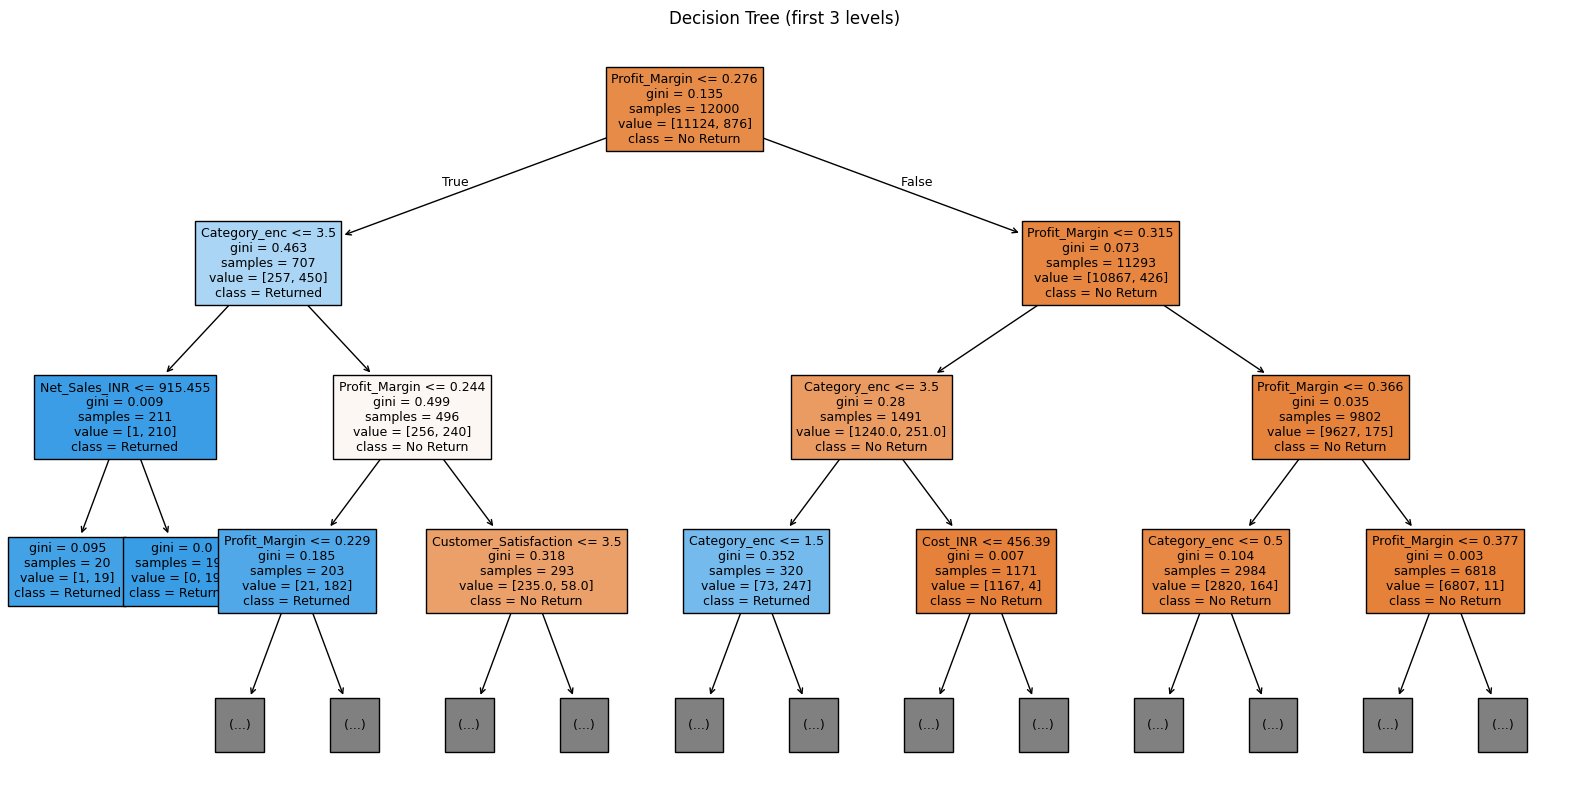

In [18]:
# Feature importance
imp = pd.Series(dt.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
imp.head(15).plot(kind='barh', color='teal')
plt.title('Decision Tree — Top Feature Importances')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()

# Tree plot (limited depth)
plt.figure(figsize=(20, 10))
plot_tree(dt, feature_names=list(X.columns),
          class_names=['No Return','Returned'],
          filled=True, max_depth=3, fontsize=9)
plt.title('Decision Tree (first 3 levels)')
plt.show()

###4.5 Confusion Matrices

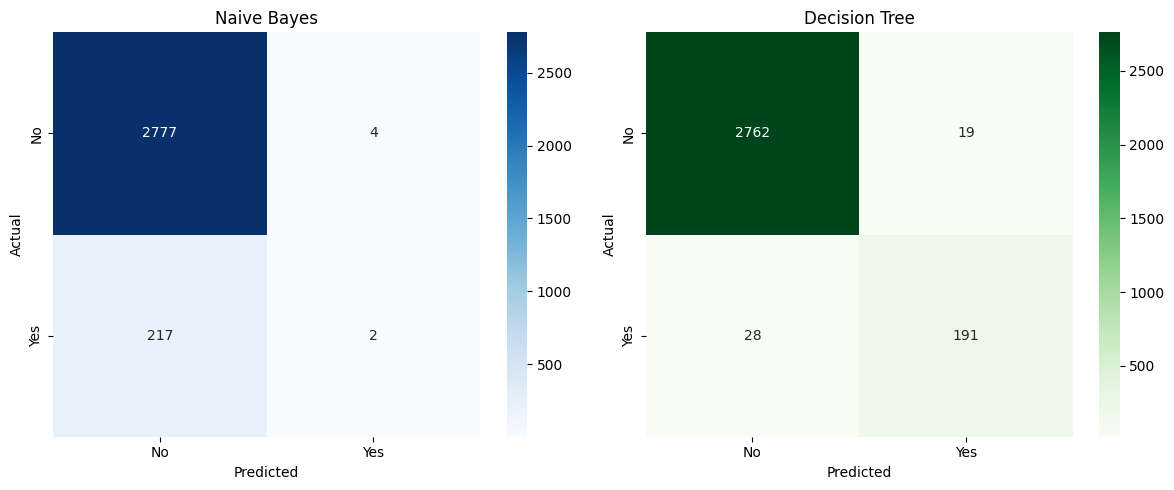

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_nb = confusion_matrix(y_test, y_pred_nb)
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No','Yes'], yticklabels=['No','Yes'], ax=axes[0])
axes[0].set_title('Naive Bayes'); axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

cm_dt = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Greens',
            xticklabels=['No','Yes'], yticklabels=['No','Yes'], ax=axes[1])
axes[1].set_title('Decision Tree'); axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Actual')

plt.tight_layout(); plt.show()

###4.6 Classifier Comparison Table


In [20]:
def clf_metrics(name, y_true, y_pred, y_prob):
    return {
        'Model': name,
        'Accuracy': round(accuracy_score(y_true, y_pred), 4),
        'Precision': round(precision_score(y_true, y_pred, zero_division=0), 4),
        'Recall': round(recall_score(y_true, y_pred, zero_division=0), 4),
        'F1': round(f1_score(y_true, y_pred, zero_division=0), 4),
        'ROC-AUC': round(roc_auc_score(y_true, y_prob), 4),
    }

cmp_df = pd.DataFrame([
    clf_metrics('Naive Bayes', y_test, y_pred_nb, y_prob_nb),
    clf_metrics('Decision Tree', y_test, y_pred_dt, y_prob_dt),
])
print("\n=== CLASSIFIER COMPARISON ===")
print(cmp_df.to_string(index=False))


=== CLASSIFIER COMPARISON ===
        Model  Accuracy  Precision  Recall     F1  ROC-AUC
  Naive Bayes    0.9263     0.3333  0.0091 0.0178   0.8094
Decision Tree    0.9843     0.9095  0.8721 0.8904   0.9919


#5. Final Combined Summary

In [21]:
print("\n" + "="*70)
print("FINAL COMPARATIVE SUMMARY")
print("="*70)

print("\n--- ARM ALGORITHMS ---")
print(arm_df.to_string(index=False))

print("\n--- CLASSIFIERS ---")
print(cmp_df.to_string(index=False))

print("\n--- TOP 5 BUSINESS RULES (from FP-Growth) ---")
top_rules = rules_fp.sort_values('lift', ascending=False).head(5)
for _, r in top_rules.iterrows():
    print(f"  {set(r['antecedents'])} -> {set(r['consequents'])}  "
          f"(sup={r['support']:.3f}, conf={r['confidence']:.3f}, lift={r['lift']:.2f})")


FINAL COMPARATIVE SUMMARY

--- ARM ALGORITHMS ---
          Algorithm  Time (s)  Freq Itemsets  Rules  Avg Lift  Max Lift  Avg Confidence
            Apriori     0.166            233    382     1.024     1.094           0.254
          FP-Growth    18.954            233    382     1.024     1.094           0.254
                DIC     0.487            233    382     1.024     1.094           0.254
Partitioned Apriori     0.498            233    382     1.024     1.094           0.254

--- CLASSIFIERS ---
        Model  Accuracy  Precision  Recall     F1  ROC-AUC
  Naive Bayes    0.9263     0.3333  0.0091 0.0178   0.8094
Decision Tree    0.9843     0.9095  0.8721 0.8904   0.9919

--- TOP 5 BUSINESS RULES (from FP-Growth) ---
  {'Chan_Retail Store'} -> {'Reg_Central', 'Seg_Consumer'}  (sup=0.022, conf=0.098, lift=1.09)
  {'Reg_Central', 'Seg_Consumer'} -> {'Chan_Retail Store'}  (sup=0.022, conf=0.242, lift=1.09)
  {'Technology_Phones'} -> {'Pay_UPI'}  (sup=0.027, conf=0.385, lift=1.09)

# MAFIA AND CHARM IMPLEMENTATION

In [22]:
# ============================================================
# MAFIA & CHARM — Vertical Mining Algorithms
# ============================================================
import time

# --- Build tidsets ---
tidsets = {}
for col in basket_df.columns:
    tidsets[col] = set(np.where(basket_df[col].values == 1)[0])

n_trans = len(basket_df)

# --- MAFIA ---
def mafia_algorithm(tidsets, min_support):
    min_count = int(min_support * n_trans)
    mfi = set()
    items = sorted(tidsets.keys(), key=lambda x: len(tidsets[x]))

    def hut_frequent(head, tail):
        combined = None
        for it in list(head) + list(tail):
            combined = tidsets[it].copy() if combined is None else combined & tidsets[it]
            if not combined:
                return False, set()
        return len(combined) >= min_count, combined

    def is_superset_in_mfi(c):
        return any(c.issubset(m) for m in mfi)

    def rec(head, tail, head_tids):
        nonlocal mfi
        hut = head | tail
        if is_superset_in_mfi(hut):
            return
        hut_freq, hut_tids = hut_frequent(head, tail)
        if hut_freq:
            mfi = {m for m in mfi if not m.issubset(hut)}
            mfi.add(frozenset(hut))
            return

        new_head = set(head)
        new_head_tids = head_tids.copy() if head_tids else None
        remaining = []
        for it in tail:
            if head_tids and tidsets[it] == head_tids:
                new_head.add(it)
            else:
                remaining.append(it)
        if new_head != head:
            nt = None
            for it in new_head:
                nt = tidsets[it].copy() if nt is None else nt & tidsets[it]
            new_head_tids = nt

        if not remaining:
            if not is_superset_in_mfi(new_head):
                mfi = {m for m in mfi if not m.issubset(new_head)}
                mfi.add(frozenset(new_head))
            return

        for i, it in enumerate(remaining):
            nt = (new_head_tids & tidsets[it]) if new_head_tids else tidsets[it]
            if len(nt) < min_count:
                continue
            rec(new_head | {it}, set(remaining[i+1:]), nt)

    rec(set(), set(items), None)
    return mfi

t0 = time.time()
mfi_result = mafia_algorithm(tidsets, 0.02)
t_mafia = time.time() - t0
print(f"MAFIA: {len(mfi_result)} MFI in {t_mafia:.2f}s")

# --- CHARM ---
def charm_algorithm(tidsets, min_support):
    min_count = int(min_support * n_trans)
    fci = {}
    results = []

    def hkey(tids): return sum(tids)

    def subsumed(itemset, support, hk):
        if hk in fci:
            for ex, ex_sup in fci[hk]:
                if ex_sup == support and itemset.issubset(ex):
                    return True
        return False

    def save(itemset, tids):
        sup = len(tids)
        if sup < min_count: return
        hk = hkey(tids)
        if not subsumed(itemset, sup, hk):
            fci.setdefault(hk, []).append((frozenset(itemset), sup))
            results.append((frozenset(itemset), sup))

    def rec(prefix, class_):
        class_ = sorted(class_, key=lambda x: len(x[1]))
        for i in range(len(class_)):
            item_i, tids_i = class_[i]
            new_prefix = prefix | {item_i}
            if subsumed(new_prefix, len(tids_i), hkey(tids_i)):
                continue
            new_class = []
            for j in range(i + 1, len(class_)):
                item_j, tids_j = class_[j]
                inter = tids_i & tids_j
                if len(inter) < min_count: continue
                if tids_i == tids_j:
                    new_prefix |= {item_j}; tids_i = inter
                elif tids_i < tids_j:
                    new_prefix |= {item_j}; tids_i = inter
                elif tids_i > tids_j:
                    new_class.append((frozenset(new_prefix | {item_j}), inter))
                else:
                    new_class.append((frozenset({item_j}) - new_prefix, inter))
            save(new_prefix, tids_i)
            if new_class:
                rec(new_prefix, new_class)

    initial = [(frozenset({it}), tids) for it, tids in tidsets.items()
               if len(tids) >= min_count]
    rec(frozenset(), initial)
    return results

t0 = time.time()
fci_result = charm_algorithm(tidsets, 0.02)
t_charm = time.time() - t0
print(f"CHARM: {len(fci_result)} FCI in {t_charm:.2f}s")

MAFIA: 6 MFI in 0.28s
CHARM: 233 FCI in 0.16s
